In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [6]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [7]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [9]:
#Part 1: Understanding Product Categories

#Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

#1. Frequency Tables:
#    - Generate a frequency table for the product `category`.
#    - Which are the top 5 most listed product categories?

category_counts = df["category"].value_counts()

category_counts

top_5_categories = category_counts.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [25]:
category_proportions = (
    df["category"]
    .value_counts(normalize=True)
    .round(4) * 100
)

category_proportions.head(5)

category
Sports & Outdoors                         34.22
Beauty                                     0.79
Handmade Clothing, Shoes & Accessories     0.79
Bath & Body                                0.78
Birthday Gifts                             0.78
Name: proportion, dtype: float64

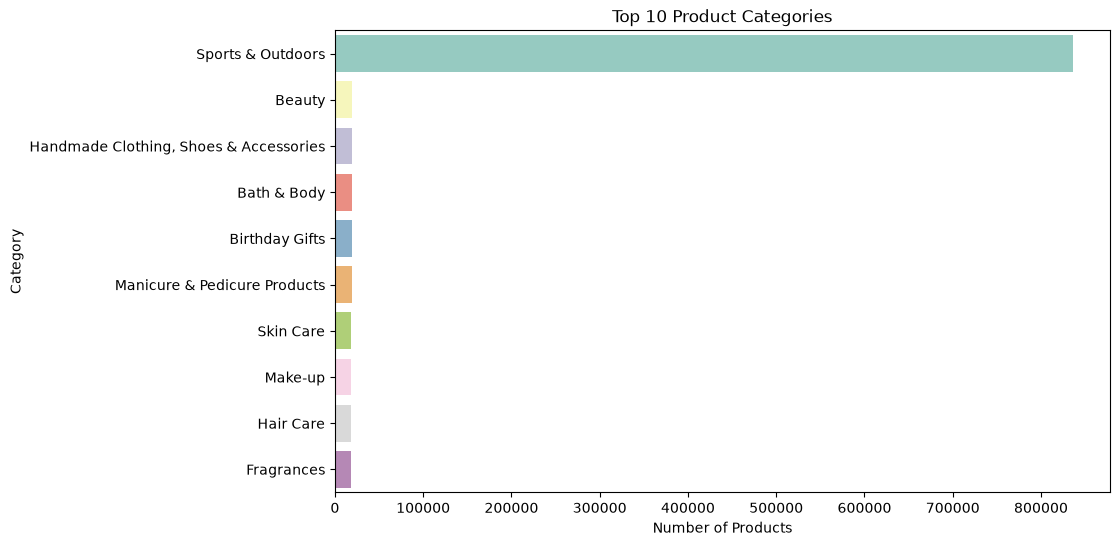

In [26]:
#2. **Visualizations**:
#    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
top_10_categories = category_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index,
    hue=top_10_categories.index,
    palette="Set3",
    legend=False
)

plt.title("Top 10 Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.show()

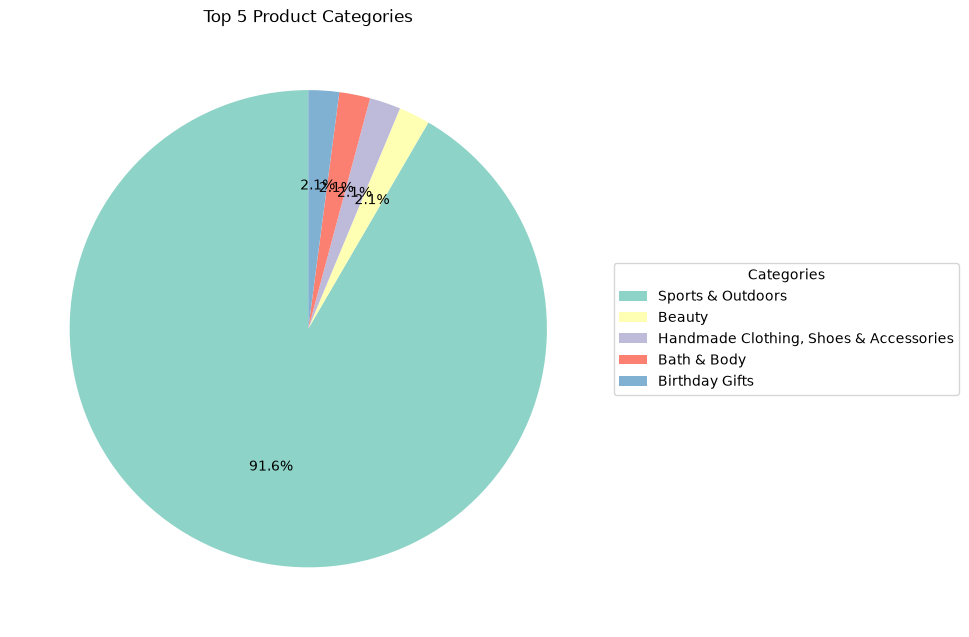

In [28]:
plt.figure(figsize=(9, 7))

top_5_categories.plot.pie(
    autopct="%.1f%%",
    startangle=90,
    colors=sns.color_palette("Set3"),
    labels=None  # Remove long names from the pie
)

plt.title("Top 5 Product Categories")
plt.ylabel("")

plt.legend(
    labels=top_5_categories.index,
    title="Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()

In [29]:
df["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

Mean price: 89.24
Median price: 19.09
Mode price: 9.99
Variance: 119445.49
Standard deviation: 345.61
Minimum: 0.0
Maximum: 100000.0
Range: 100000.0
Quantiles:
0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64
IQR: 36.0


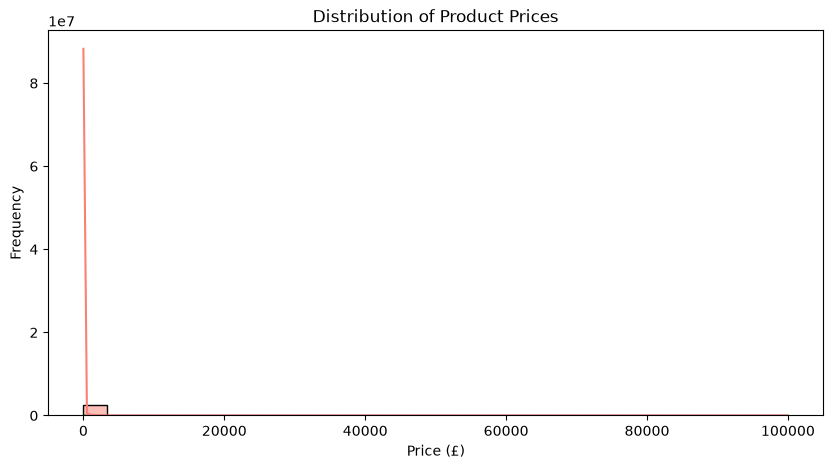

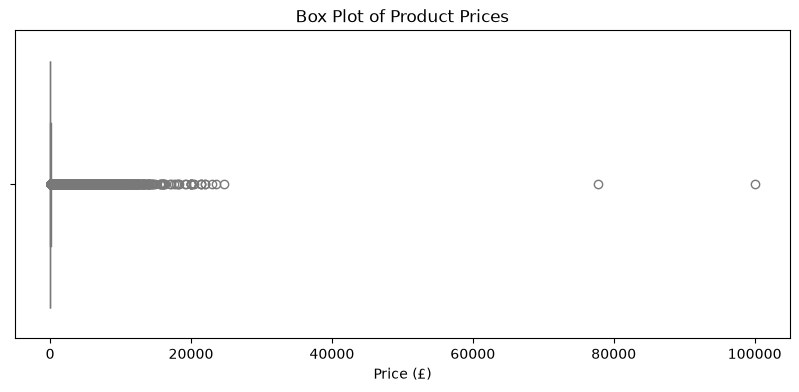

In [32]:
#Part 2: Delving into Product Pricing

#Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

df["price"] = pd.to_numeric(
    df["price"],
    errors="coerce"
)
prices = df["price"].dropna()


#1. Measures of Centrality:
#    - Calculate the mean, median, and mode for the `price` of products.
price_mean = prices.mean()
price_median = prices.median()
price_mode = prices.mode().iloc[0]

print("Mean price:", round(price_mean, 2))
print("Median price:", round(price_median, 2))
print("Mode price:", round(price_mode, 2))
#    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

#2. **Measures of Dispersion**:
#    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
variance_price = df["price"].var()
std_price = df["price"].std()

min_price = df["price"].min()
max_price = df["price"].max()
range_price = max_price - min_price

quantiles_price = df["price"].quantile([0.25, 0.5, 0.75])

q1_price = df["price"].quantile(0.25)
q3_price = df["price"].quantile(0.75)
iqr_price = q3_price - q1_price


print("Variance:", round(variance_price, 2))
print("Standard deviation:", round(std_price, 2))
print("Minimum:", min_price)
print("Maximum:", max_price)
print("Range:", range_price)
print("Quantiles:")
print(quantiles_price)
print("IQR:", round(iqr_price, 2))

#    - How varied are the product prices? Are there any indicators of a significant spread in prices?

#3. **Visualizations**:
#    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
fig, axes = plt.subplots(figsize=(10, 5))

sns.histplot(
    df["price"],
    kde=True,
    bins=30,
    color="salmon",
    ax=axes
)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()

#    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 
fig, axes = plt.subplots(figsize=(10, 4))

sns.boxplot(
    x=df["price"],
    color="lightblue",
    ax=axes
)

plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.show()

Mean rating: 2.15
Median rating: 0.0
Mode rating: 0.0
Variance: 4.82
Standard deviation: 2.19
Q1: 0.0
Q3: 4.4
IQR: 4.4
Skewness: 0.08
Kurtosis: -1.93


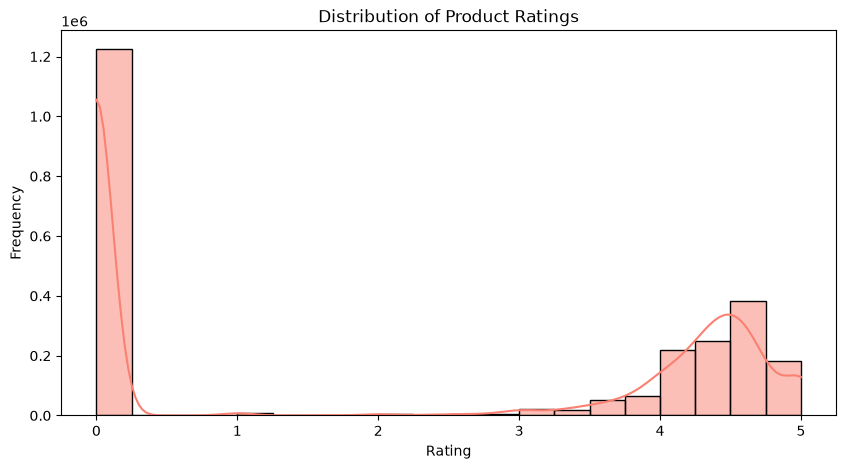

In [40]:
# Part 3: Unpacking Product Ratings
# Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

# Measures of Centrality:
df["stars"].describe()
#df["stars"].value_counts().sort_index()
(df["stars"] == 0).sum()
# Calculate the mean, median, and mode for the rating of products.
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print("Mean rating:", round(mean_rating, 2))
print("Median rating:", round(median_rating, 2))
print("Mode rating:", round(mode_rating, 2))
# How do customers generally rate products? Is there a common trend?
# Measures of Dispersion:

# Determine the variance, standard deviation, and interquartile range for product rating.
variance_rating = df["stars"].var()
std_rating = df["stars"].std()

q1_rating = df["stars"].quantile(0.25)
q3_rating = df["stars"].quantile(0.75)
iqr_rating = q3_rating - q1_rating


print("Variance:", round(variance_rating, 2))
print("Standard deviation:", round(std_rating, 2))
print("Q1:", q1_rating)
print("Q3:", q3_rating)
print("IQR:", round(iqr_rating, 2))
# Are the ratings consistent, or is there a wide variation in customer feedback?
# Shape of the Distribution:

# Calculate the skewness and kurtosis for the rating column.
skewness_rating = df["stars"].skew()
kurtosis_rating = df["stars"].kurtosis()

print("Skewness:", round(skewness_rating, 2))
print("Kurtosis:", round(kurtosis_rating, 2))

# Are the ratings normally distributed, or do they lean towards higher or lower values?
# Visualizations:

# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

fig, axes = plt.subplots(figsize=(10, 5))

sns.histplot(
    df["stars"],
    kde=True,
    bins=20,
    color="salmon",
    ax=axes
)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()